# DSMEM collectives inside one H100 thread-block cluster

29 implementations of four collectives run inside **one thread-block cluster** of N = 2, 4, 8 or 16 CTAs (one CTA
per SM) and exchange their data through **distributed shared memory (DSMEM)**: each CTA reads or writes the shared
memory of its peers directly. Each CTA holds its data in its own shared memory; one launch runs one collective once.
Latency comes from `%globaltimer` stamps that every CTA writes; DSMEM traffic from Nsight Compute.

In [1]:
import collectives_figures as cf
D = cf.load()

## Setup

In [2]:
cf.table_setup(D)

,value
,
GPU,"NVIDIA H100 NVL (GPU 3, 132 SMs)"
Driver / CUDA runtime,580.126.20 / 12.9
Toolchain,"nvcc 12.9.86, -arch=sm_90a -O3; Nsight Compute..."
SM clock,locked at 1635 MHz (median sample 1635 MHz); m...
Launch,"one cluster of N CTAs, 256 threads per CTA, dy..."
Configurations,"643 (file × N × payload), float"
Timed launches,"257200 (2 sweeps × 200 per configuration, rand..."
Sweep run_ids,"2026-10-25T23:30:35.666+00:00, 2026-10-25T23:4..."
Timer,"%globaltimer, 32 ns resolution"


## Definitions

| Symbol | Meaning |
|---|---|
| N | CTAs in the cluster (ranks), one per SM |
| M, B | elements per message (`MSG_ELEMS`), bytes per element (B = 4, float) |
| P | payload per CTA, the data size of nccl-tests: allreduce M·B; allgather N·M·B (the gathered output); reducescatter and alltoall N·M·B (the input) |
| L | collective latency of one launch = max over ranks of the exit stamp − min over ranks of the entry stamp |
| L_r | latency of rank r = its exit stamp − its entry stamp |
| algbw | P / L |
| busbw | algbw × f, with f = 2(N−1)/N for allreduce and (N−1)/N for the others: the rate at which a traffic-optimal algorithm drives each SM's link, comparable across ops and N |
| injection bandwidth | S_r / L_r, where S_r = DSMEM bytes leaving SM r (traffic model) |

The entry stamp is taken after the cluster barrier that follows loading the input into shared memory; the exit stamp
after the collective's last synchronisation. Every number is the median (with p10–p90 where shown) over 400 launches:
two sweeps of 200 timed launches after 20 warm-ups, in randomised order. The timer resolution is 32 ns.

## Algorithms

"Sync inside" is how ranks synchronise *between* the entry and exit stamps (every kernel also has one cluster barrier
before and one after the timed region). "mbarrier only": a sender's bulk copy completes the bytes on the receiver's
mbarrier, so only the receiver waits. "barrier per round": all CTAs meet at a cluster-wide barrier after every round.

| op | algorithm | pattern | rounds | sync inside |
|---|---|---|---|---|
| allreduce | two_shot_push | direct reduce-scatter push, then direct all-gather push | 2 | mbarrier only |
| | 2d_mesh | R×C grid: row reduce-scatter, column allreduce, row all-gather | 3 | mbarrier only |
| | one_shot_pull | every CTA reads all peers' vectors and reduces locally | 1 | 2 cluster barriers |
| | direct_replicated_push | every CTA stores its vector into every peer, local reduce | 1 | 2 cluster barriers |
| | pull_reduce_scatter_push_allgather | pull own chunk from all peers, reduce, push it back | 1 | 2 cluster barriers |
| | atomic_all_push | remote atomic adds into every peer | 1 | 2 cluster barriers |
| | ring | ring reduce-scatter + ring all-gather | 2(N−1) | barrier per round |
| | rabenseifner | recursive halving + recursive doubling | 2 log₂N | barrier per round |
| | recursive_doubling | full vector to shift 1, 2, 4, … | log₂N | barrier per round |
| | reduce_bcast_binomial | binomial reduce to rank 0, then broadcast | 2 log₂N | barrier per round |
| | shift_accumulate_bulk | running sum forwarded by shifts (N = 4 only) | N−2 | barrier per round |
| | shift_accumulate_atomic | shifts with remote atomic adds (N = 2, 4) | N−2 (1 at N = 2) | 2 barriers per round |
| allgather | direct_replicated_push | every CTA stores its block into every peer | 1 | 1 cluster barrier |
| | direct_pull | every CTA reads every peer's block | 1 | 2 cluster barriers |
| | recursive_doubling | block count doubles each round | log₂N | barrier per round |
| | bruck | shifts double each round, final un-rotation | ⌈log₂N⌉ | barrier per round |
| | ring | forward one block per round | N−1 | barrier per round |
| | direct_shift | own block to shift i | N−1 | 2 barriers per round |
| | gather_bcast_binomial | binomial gather to rank 0, then broadcast of the full buffer | 2 log₂N | barrier per round |
| reducescatter | direct_push | push chunk j to rank j | 1 | mbarrier only |
| | direct_pull | read own chunk from every peer | 1 | 2 cluster barriers |
| | recursive_halving | exchange halves | log₂N | barrier per round |
| | ring | ring | N−1 | barrier per round |
| alltoall | direct_push | push chunk j to rank j | 1 | mbarrier only |
| | pairwise_exchange | swap halves (N = 2 only) | 1 | mbarrier only |
| | direct_pull | read chunk from every peer | 1 | 2 cluster barriers |
| | pairwise_xor | partner rank ⊕ i | N−1 | barrier per round |
| | shift | partner rank + i | N−1 | barrier per round |
| | bruck | shifts double, half the blocks per round | log₂N | 2 barriers per round |

## Findings

- **Synchronisation style decides small-message latency.** Up to 4 KiB per CTA the fastest algorithm of every op is a
  single exchange without a barrier per round: allreduce two_shot_push / 2d_mesh 0.35–0.99 µs, reducescatter
  direct_push 0.22–0.80 µs, alltoall direct_push / pairwise_exchange 0.16–0.70 µs, allgather direct_replicated_push
  0.42–0.86 µs (N = 2–16; at N = 2, 4 KiB Bruck, also a single exchange there, is fastest).
- **A barrier per round costs ≈ 0.5–0.6 µs per round at 4 KiB.** Ring allreduce takes 0.52–0.62 µs per round, so it
  grows from 1.25 µs at N = 2 to 17.5 µs at N = 16 (30 rounds), while two_shot_push grows from 0.51 to 1.41 µs.
  Remote atomics (atomic_all_push) are the slowest: 13 µs at N = 8.
- **Peak bus bandwidth:** allreduce 25 GB/s (two_shot_push, N = 8, 64 KiB), allgather 29 GB/s (ring, N = 2, 227 KiB),
  reducescatter 22 GB/s (direct_push, N = 8, 64 KiB), alltoall 30 GB/s (direct_push, N = 4, 64 KiB).
- **Per SM**, the best algorithms at N = 16 drive each SM's link at 16–20 GB/s (median over ranks and launches).
- **Measured DSMEM traffic equals the traffic model** within 10 % for 507 of 643 configurations and is never below
  it. The rest are counted in larger units than the payload (transfers below 32 B, remote atomics, lane-interleaved
  scalar accesses) or are the largest-payload points, whose sizes are not multiples of 128 B (section 6).

## 1. Latency vs cluster size

Median collective latency L (line) and p10–p90 (band) of every algorithm at 4 KiB per CTA.

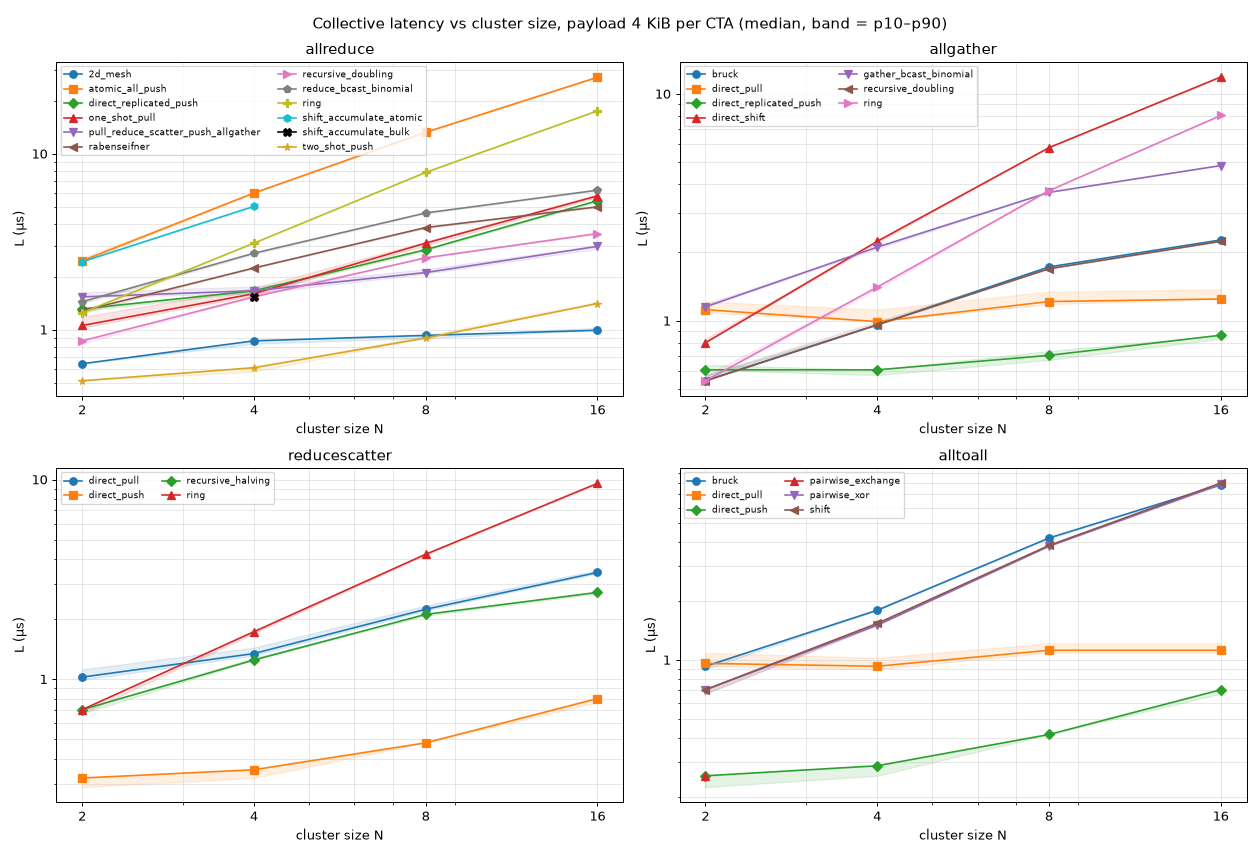

In [3]:
cf.fig_latency_vs_n(D)

Single-exchange algorithms without a barrier per round grow slowest with N (under 1.5 µs up to N = 16); algorithms
with a barrier per round grow with their round count: about N for ring, pairwise_xor, shift and direct_shift, about
log₂N for recursive doubling, Bruck and recursive halving. The bands are narrow: p90 is within 1 % of the median for
half the configurations and within 9.4 % for 95 %; the widest (33 %) are sub-300 ns latencies, where one 32-ns timer
tick is a large fraction.

## 2. Latency vs payload

Median latency against payload per CTA at N = 8 and N = 16. The open marker at the end of each line is the largest
payload whose buffers fit the 227 KiB of shared memory one CTA can use.

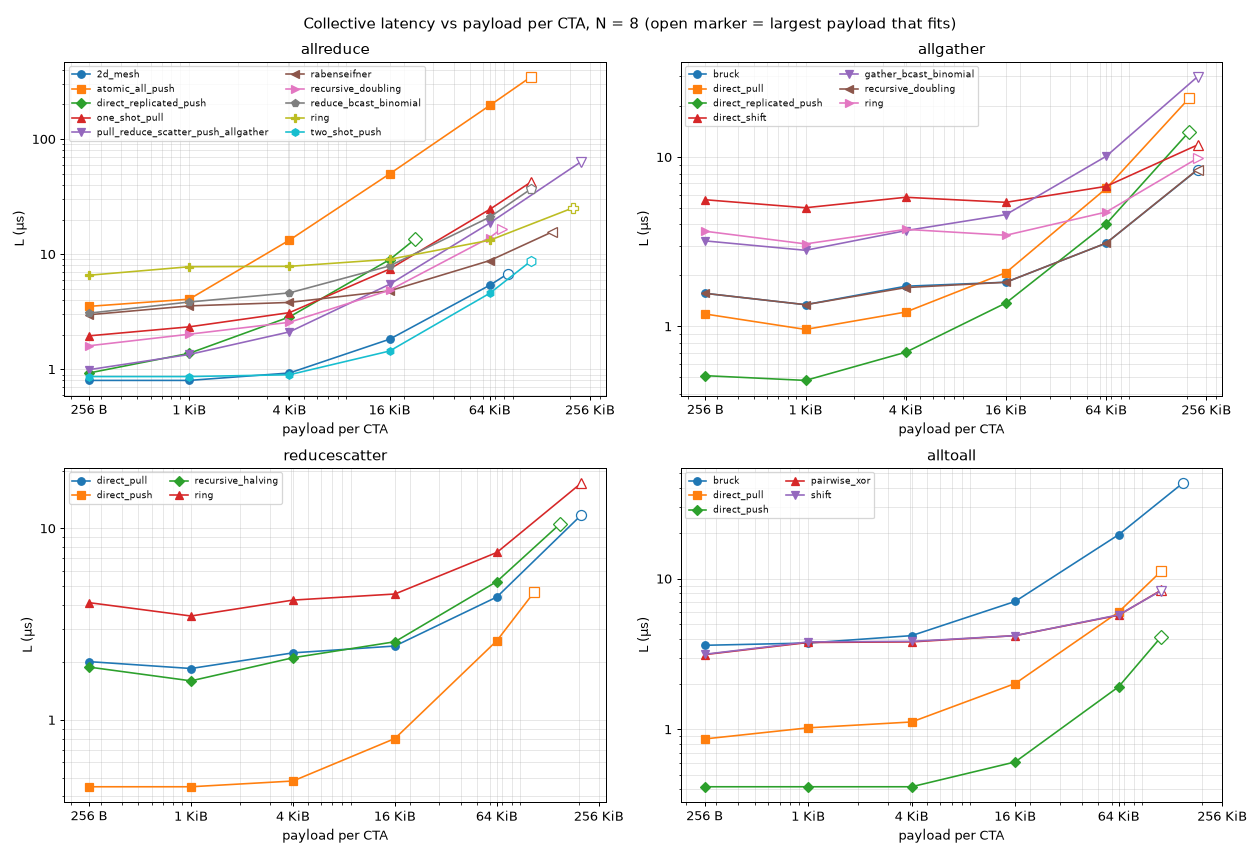

In [4]:
cf.fig_latency_vs_payload(D, 8)

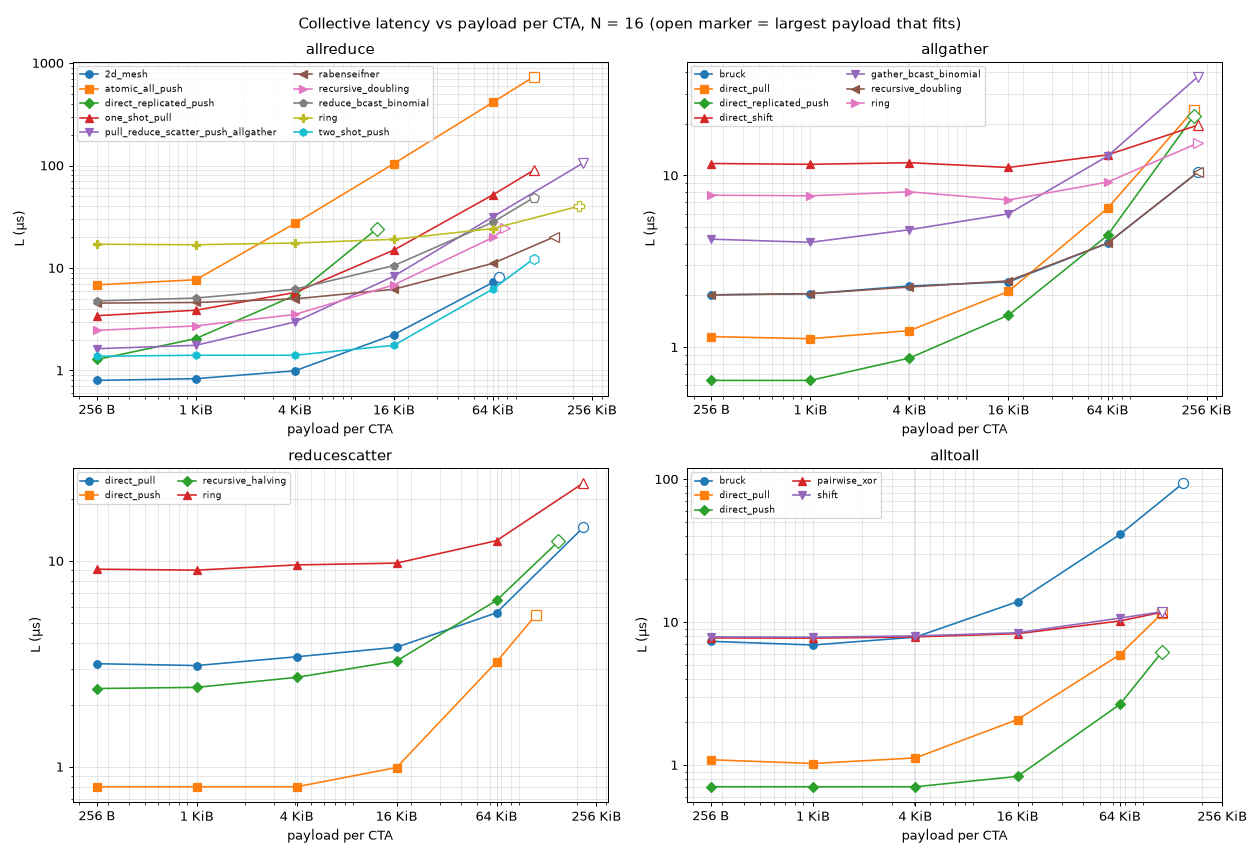

In [5]:
cf.fig_latency_vs_payload(D, 16)

Each curve is flat while synchronisation dominates and then rises roughly in proportion to the bytes moved. Algorithms
with a barrier per round stay flat at a much higher floor (ring allreduce ≈ 6.5–9 µs at N = 8 up to 16 KiB), so they
only become competitive at the largest payloads.

## 3. Bus bandwidth vs payload

busbw at N = 8. Solid lines: algorithms whose every rank sends exactly the minimum traffic of the op
(traffic-optimal); dashed: algorithms that move more in total or unevenly across ranks.

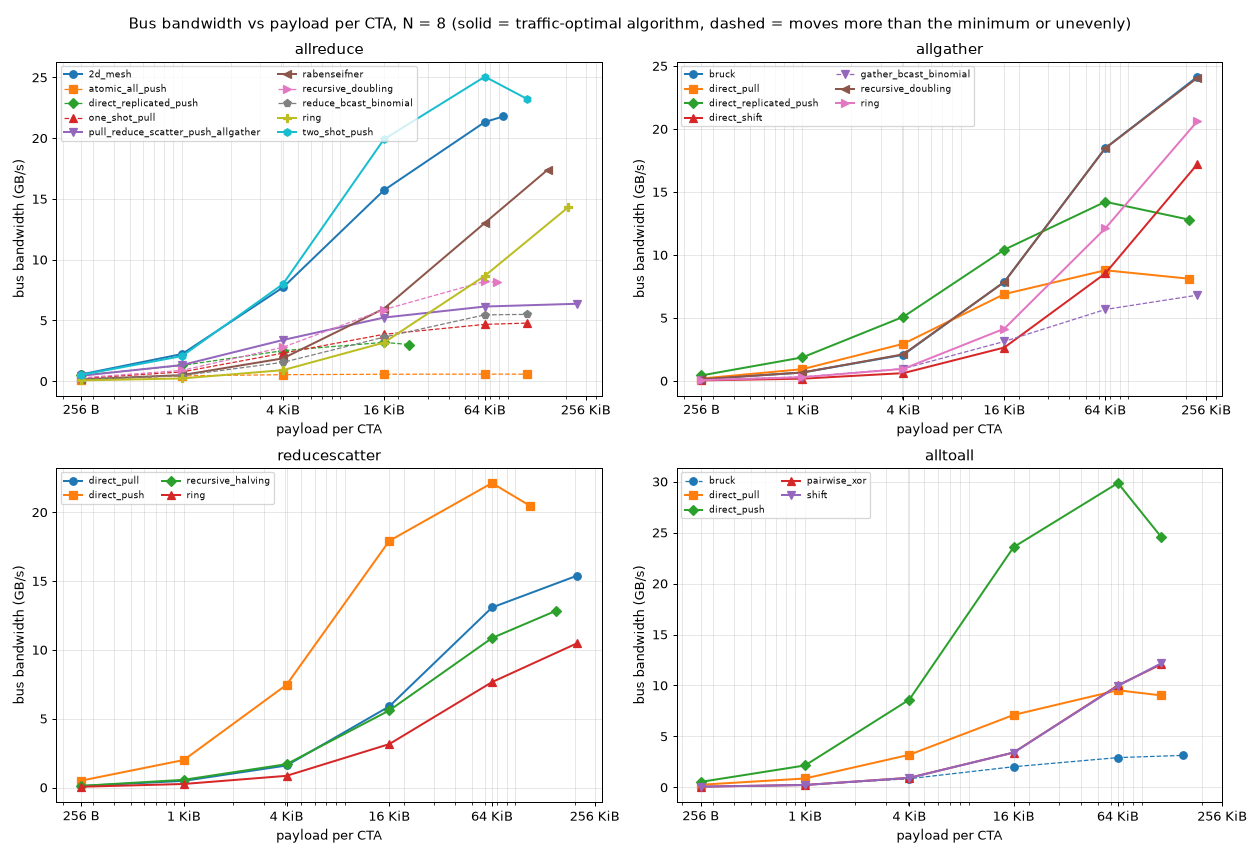

In [6]:
cf.fig_busbw_vs_payload(D)

Bandwidth rises with payload as the fixed synchronisation cost is amortised. The single-exchange pushes reach
22–30 GB/s at 64 KiB; dashed algorithms flatten early (atomic_all_push below 1 GB/s, reduce_bcast_binomial and
one_shot_pull ≈ 5 GB/s). Some curves dip at the largest payload point.

## 4. Per-rank timeline

One launch of median latency per op, N = 8, 4 KiB per CTA. Each row is a rank (labelled with its SM): entry (|),
the end of each round (•), exit (▶).

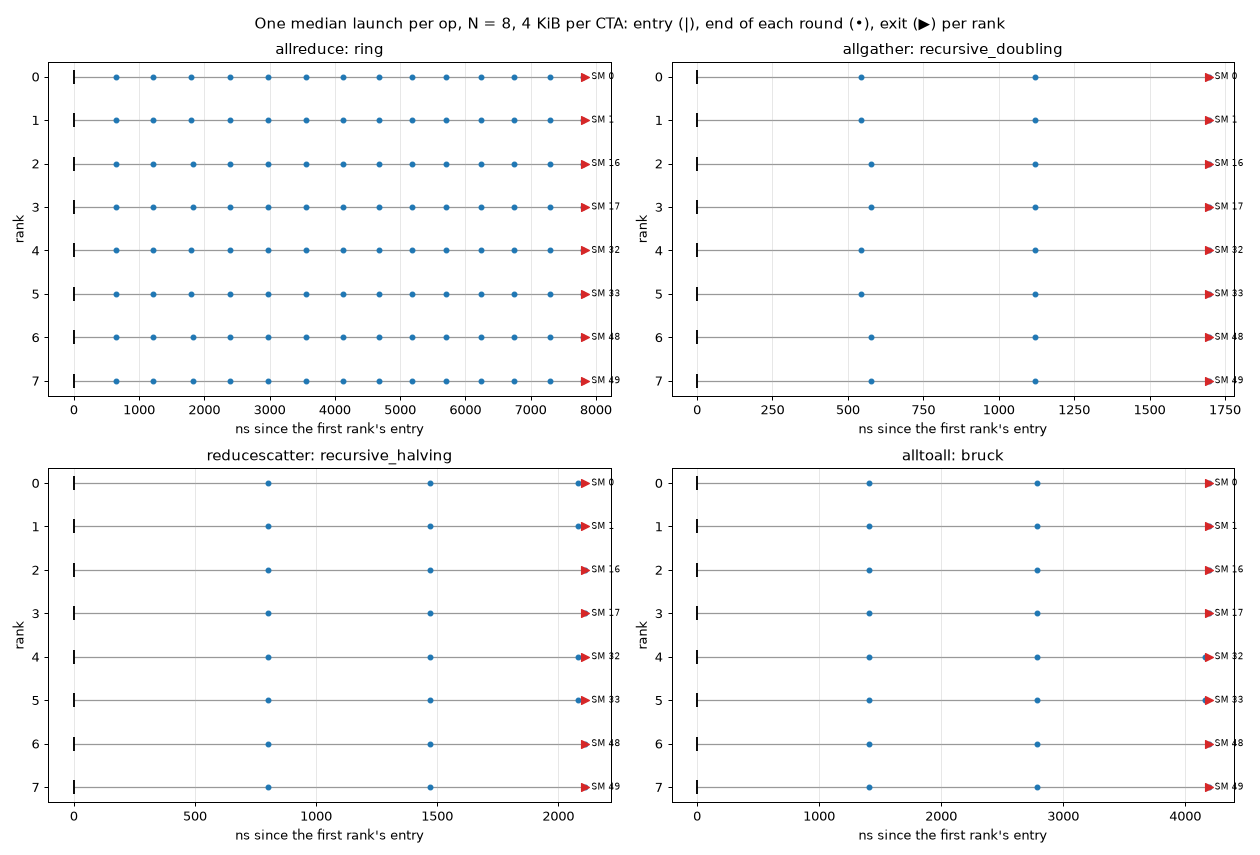

In [7]:
cf.fig_rank_timeline(D)

With a barrier after every round the ranks advance in lock-step: the round stamps of all ranks line up and every round
takes the same time (ring allreduce: 14 rounds of ≈ 0.56 µs). The 8 CTAs occupy SMs 0, 1, 16, 17, 32, 33, 48, 49,
i.e. pairs of SMs that share a TPC.

## 5. Per-SM injection bandwidth

Bytes each rank sends (traffic model) divided by that rank's own latency L_r, at N = 16 and 16 KiB per CTA; one box
per algorithm over all ranks and launches.

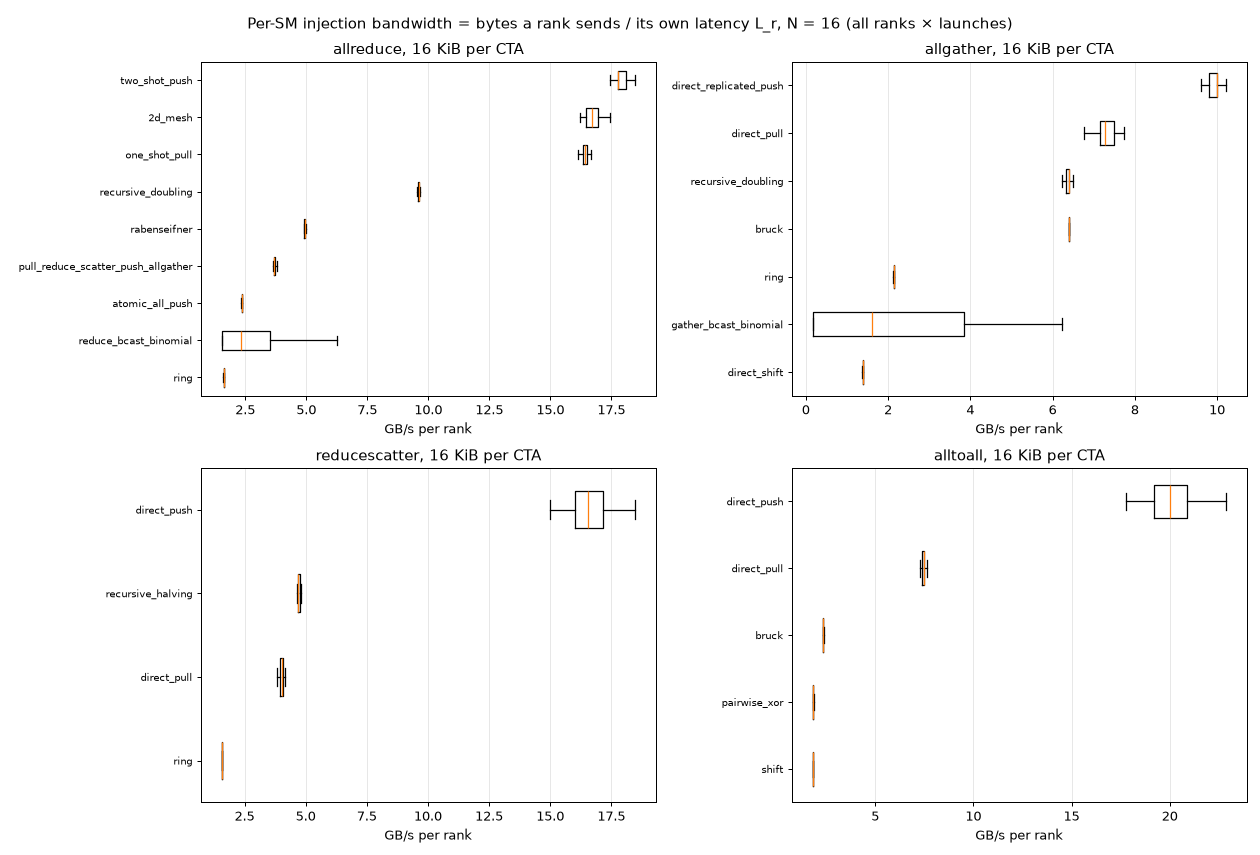

In [8]:
cf.fig_injection_bw(D)

The single-exchange pushes drive each SM at 16–20 GB/s; algorithms with many barrier-separated rounds stay at
1.5–10 GB/s. Rooted trees (reduce_bcast_binomial, gather_bcast_binomial) spread widely because their ranks send very
different amounts.

## 6. Measured DSMEM traffic vs model

Kernel-wide DSMEM bytes counted by Nsight Compute (`l1tex__m_l1tex2xbar_write_bytes_mem_dshared.sum`, minus a launch
of an empty kernel with the same grid) against the traffic model (sum over ranks of the bytes each rank sends), for
every configuration; right: the range of the ratio per algorithm.

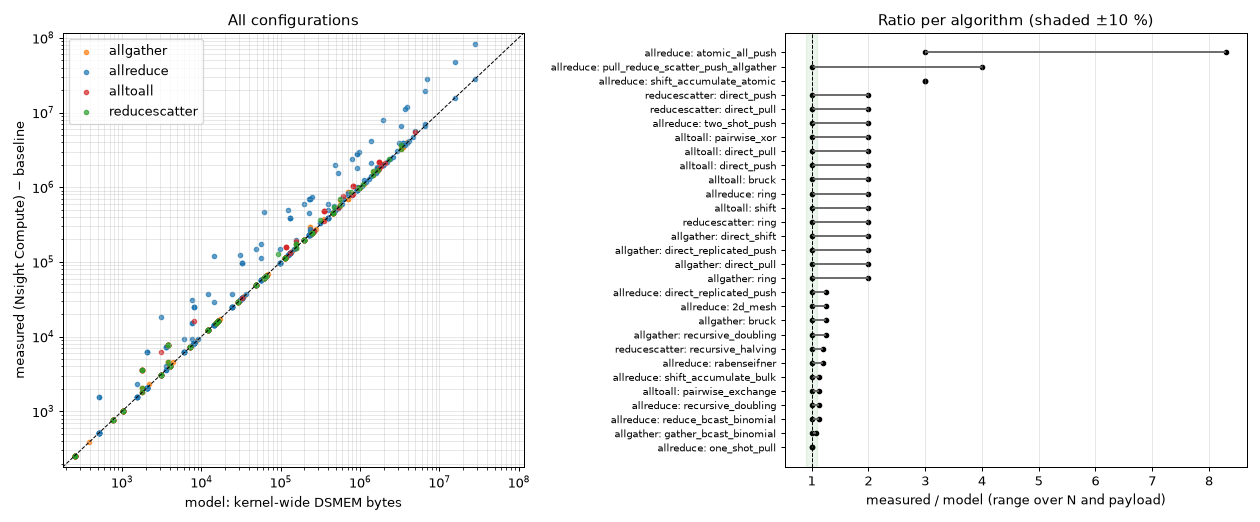

In [9]:
cf.fig_traffic_vs_model(D)

Most points lie on the diagonal. The deviations are all above it:
- **Transfers below 32 B** (e.g. 16-B chunks at the smallest payloads) are counted as a full 32-B sector: 2×.
- **Remote atomics** (atomic_all_push, shift_accumulate_atomic) are counted at 3× the payload (atomic_all_push: 2× as
  atomic traffic and 1× as loads).
- **pull_reduce_scatter_push_allgather** accesses 4-byte elements with consecutive lanes on different peers: 1× at
  N = 2, growing to 4× at N = 16.
- **The largest-payload points** of the bulk-copy algorithms, whose message sizes and buffer offsets are not
  multiples of 128 B, read 6–38 % above the model.

## 7. Best algorithm per op, cluster size and payload

Lowest median latency:

In [10]:
cf.table_best(D, "latency")

256 B  \
op            N                                      
allreduce     2            two_shot_push (0.35 µs)   
              4            two_shot_push (0.51 µs)   
              8                   2d_mesh (0.8 µs)   
              16                  2d_mesh (0.8 µs)   
allgather     2   direct_replicated_push (0.42 µs)   
              4   direct_replicated_push (0.48 µs)   
              8   direct_replicated_push (0.51 µs)   
              16  direct_replicated_push (0.64 µs)   
reducescatter 2              direct_push (0.22 µs)   
              4              direct_push (0.32 µs)   
              8              direct_push (0.45 µs)   
              16              direct_push (0.8 µs)   
alltoall      2        pairwise_exchange (0.16 µs)   
              4              direct_push (0.29 µs)   
              8              direct_push (0.42 µs)   
              16              direct_push (0.7 µs)   

                                             1 KiB  \
op            N                                      
allreduce     2            two_shot_push (0.38 µs)   
              4            two_shot_push (0.54 µs)   
              8                   2d_mesh (0.8 µs)   
              16                 2d_mesh (0.83 µs)   
allgather     2   direct_replicated_push (0.45 µs)   
              4   direct_replicated_push (0.42 µs)   
              8   direct_replicated_push (0.48 µs)   
              16  direct_replicated_push (0.64 µs)   
reducescatter 2              direct_push (0.22 µs)   
              4              direct_push (0.32 µs)   
              8              direct_push (0.45 µs)   
              16              direct_push (0.8 µs)   
alltoall      2              direct_push (0.19 µs)   
              4              direct_push (0.29 µs)   
              8              direct_push (0.42 µs)   
              16              direct_push (0.7 µs)   

                                             4 KiB  \
op            N                                      
allreduce     2            two_shot_push (0.51 µs)   
              4            two_shot_push (0.61 µs)   
              8             two_shot_push (0.9 µs)   
              16                 2d_mesh (0.99 µs)   
allgather     2                    bruck (0.54 µs)   
              4   direct_replicated_push (0.61 µs)   
              8    direct_replicated_push (0.7 µs)   
              16  direct_replicated_push (0.86 µs)   
reducescatter 2              direct_push (0.32 µs)   
              4              direct_push (0.35 µs)   
              8              direct_push (0.48 µs)   
              16              direct_push (0.8 µs)   
alltoall      2              direct_push (0.26 µs)   
              4              direct_push (0.29 µs)   
              8              direct_push (0.42 µs)   
              16              direct_push (0.7 µs)   

                                            16 KiB  \
op            N                                      
allreduce     2            two_shot_push (1.09 µs)   
              4            two_shot_push (1.28 µs)   
              8            two_shot_push (1.44 µs)   
              16           two_shot_push (1.76 µs)   
allgather     2                    bruck (0.64 µs)   
              4   direct_replicated_push (1.22 µs)   
              8   direct_replicated_push (1.38 µs)   
              16  direct_replicated_push (1.54 µs)   
reducescatter 2               direct_push (0.7 µs)   
              4              direct_push (0.74 µs)   
              8               direct_push (0.8 µs)   
              16             direct_push (0.99 µs)   
alltoall      2        pairwise_exchange (0.42 µs)   
              4              direct_push (0.51 µs)   
              8              direct_push (0.61 µs)   
              16             direct_push (0.83 µs)   

                                       64 KiB  
op            N                                
allreduce     2       two_shot_push (3.42 µs)  
         

Highest bus bandwidth:

In [11]:
cf.table_best(D, "bandwidth")

256 B  \
op            N                                       
allreduce     2            two_shot_push (0.7 GB/s)   
              4            two_shot_push (0.8 GB/s)   
              8                  2d_mesh (0.6 GB/s)   
              16                 2d_mesh (0.6 GB/s)   
allgather     2   direct_replicated_push (0.3 GB/s)   
              4   direct_replicated_push (0.4 GB/s)   
              8   direct_replicated_push (0.4 GB/s)   
              16  direct_replicated_push (0.4 GB/s)   
reducescatter 2              direct_push (0.6 GB/s)   
              4              direct_push (0.6 GB/s)   
              8              direct_push (0.5 GB/s)   
              16             direct_push (0.3 GB/s)   
alltoall      2        pairwise_exchange (0.8 GB/s)   
              4              direct_push (0.7 GB/s)   
              8              direct_push (0.5 GB/s)   
              16             direct_push (0.3 GB/s)   

                                              1 KiB  \
op            N                                       
allreduce     2            two_shot_push (2.7 GB/s)   
              4            two_shot_push (2.8 GB/s)   
              8                  2d_mesh (2.2 GB/s)   
              16                 2d_mesh (2.3 GB/s)   
allgather     2   direct_replicated_push (1.1 GB/s)   
              4   direct_replicated_push (1.8 GB/s)   
              8   direct_replicated_push (1.9 GB/s)   
              16  direct_replicated_push (1.5 GB/s)   
reducescatter 2              direct_push (2.3 GB/s)   
              4              direct_push (2.4 GB/s)   
              8              direct_push (2.0 GB/s)   
              16             direct_push (1.2 GB/s)   
alltoall      2              direct_push (2.7 GB/s)   
              4              direct_push (2.7 GB/s)   
              8              direct_push (2.2 GB/s)   
              16             direct_push (1.4 GB/s)   

                                              4 KiB  \
op            N                                       
allreduce     2            two_shot_push (8.0 GB/s)   
              4           two_shot_push (10.1 GB/s)   
              8            two_shot_push (8.0 GB/s)   
              16                 2d_mesh (7.7 GB/s)   
allgather     2                    bruck (3.8 GB/s)   
              4   direct_replicated_push (5.1 GB/s)   
              8   direct_replicated_push (5.1 GB/s)   
              16  direct_replicated_push (4.4 GB/s)   
reducescatter 2              direct_push (6.4 GB/s)   
              4              direct_push (8.7 GB/s)   
              8              direct_push (7.5 GB/s)   
              16             direct_push (4.8 GB/s)   
alltoall      2              direct_push (8.0 GB/s)   
              4             direct_push (10.7 GB/s)   
              8              direct_push (8.6 GB/s)   
              16             direct_push (5.5 GB/s)   

                                              16 KiB  \
op            N                                        
allreduce     2            two_shot_push (15.1 GB/s)   
              4            two_shot_push (19.2 GB/s)   
              8            two_shot_push (19.9 GB/s)   
              16           two_shot_push (17.5 GB/s)   
allgather     2                    bruck (12.8 GB/s)   
              4   direct_replicated_push (10.1 GB/s)   
              8   direct_replicated_push (10.4 GB/s)   
              16  direct_replicated_push (10.0 GB/s)   
reducescatter 2              direct_push (11.6 GB/s)   
              4              direct_push (16.7 GB/s)   
              8              direct_push (17.9 GB/s)   
              16             direct_push (15.5 GB/s)   
alltoall      2        pairwise_exchange (19.7 GB/s)   
              4              direct_push (24.0 GB/s)   
              8              direct_push (23.6 GB/s)   
              16             direct_push (18.5 GB/s)   

                                         64 KiB  
op            

Median latency (µs) of every algorithm at 4 KiB per CTA:

In [12]:
cf.table_latency_4k(D)

N →  median L (µs) at 4 KiB per CTA                 2     4      8      16
op            alg                                                         
allgather     bruck                               0.54  0.96   1.73   2.27
              direct_pull                         1.12  0.99   1.22   1.25
              direct_replicated_push              0.61  0.61   0.70   0.86
              direct_shift                        0.80  2.24   5.79  11.87
              gather_bcast_binomial               1.15  2.11   3.68   4.83
              recursive_doubling                  0.54  0.96   1.70   2.24
              ring                                0.54  1.41   3.74   8.03
allreduce     2d_mesh                             0.64  0.86   0.93   0.99
              atomic_all_push                     2.46  5.98  13.25  27.23
              direct_replicated_push              1.31  1.66   2.85   5.41
              one_shot_pull                       1.06  1.60   3.10   5.76
              pull_reduce_scatter_push_allgather  1.54  1.66   2.11   2.98
              rabenseifner                        1.28  2.24   3.81   4.99
              recursive_doubling                  0.86  1.54   2.56   3.52
              reduce_bcast_binomial               1.44  2.72   4.61   6.21
              ring                                1.25  3.10   7.84  17.54
              shift_accumulate_atomic             2.43  5.02    NaN    NaN
              shift_accumulate_bulk                NaN  1.54    NaN    NaN
              two_shot_push                       0.51  0.61   0.90   1.41
alltoall      bruck                               0.93  1.79   4.19   7.84
              direct_pull                         0.96  0.93   1.12   1.12
              direct_push                         0.26  0.29   0.42   0.70
              pairwise_exchange                   0.26   NaN    NaN    NaN
              pairwise_xor                        0.70  1.50   3.81   7.87
              shift                               0.70  1.54   3.84   8.00
reducescatter direct_pull                         1.02  1.34   2.24   3.42
              direct_push                         0.32  0.35   0.48   0.80
              recursive_halving                   0.70  1.25   2.11   2.72
              ring                                0.70  1.73   4.22   9.57

The per-configuration medians and percentiles are in `results/summary_latency.csv` and `results/summary_bandwidth.csv`.

In [13]:
cf.write_summaries(D);